# Atelier d'analyse dynamique

Interface Jupyter pour explorer les donnees, ajuster une strategie de moyennes mobiles et lire des documents locaux.

In [1]:
from pathlib import Path
import sys

racine = Path.cwd().resolve()
while not (racine / "src" / "strategy.py").is_file() and racine != racine.parent:
    racine = racine.parent
sys.path.insert(0, str(racine / "src"))

from strategy import backtest_moyennes
from metrics import metriques
from document_reader import lire_document

TICKER = "AI.PA"
COURTE = 20
LONGUE = 50
COUT = 0.001

In [2]:
donnees = backtest_moyennes(
    ticker=TICKER,
    courte=COURTE,
    longue=LONGUE,
    cout=COUT,
    debut="2018-01-01",
)

display(donnees[["Close", "mm_courte", "mm_longue", "signal", "position"]].tail())
print("Strategie:", metriques(donnees["strategie"]))
print("Achat-conservation:", metriques(donnees["rendement"]))

Price,Close,mm_courte,mm_longue,signal,position
Date,,,,,
2026-11-16,193.240005,182.862001,174.292401,1,1.0
2026-11-17,190.940002,183.797001,174.648001,1,1.0
2026-11-18,189.740005,184.604001,175.076401,1,1.0
2026-11-19,189.139999,185.382001,175.523601,1,1.0
2026-11-20,187.580002,186.027001,175.944801,1,1.0


Strategie: {'Rendement annuel': np.float64(0.0131), 'Volatilité': np.float64(0.142), 'Sharpe': np.float64(0.16), 'Perte maximale': np.float64(-0.2725), 'Rendement total': np.float64(0.1245)}
Achat-conservation: {'Rendement annuel': np.float64(0.1355), 'Volatilité': np.float64(0.1967), 'Sharpe': np.float64(0.74), 'Perte maximale': np.float64(-0.2928), 'Rendement total': np.float64(2.1519)}


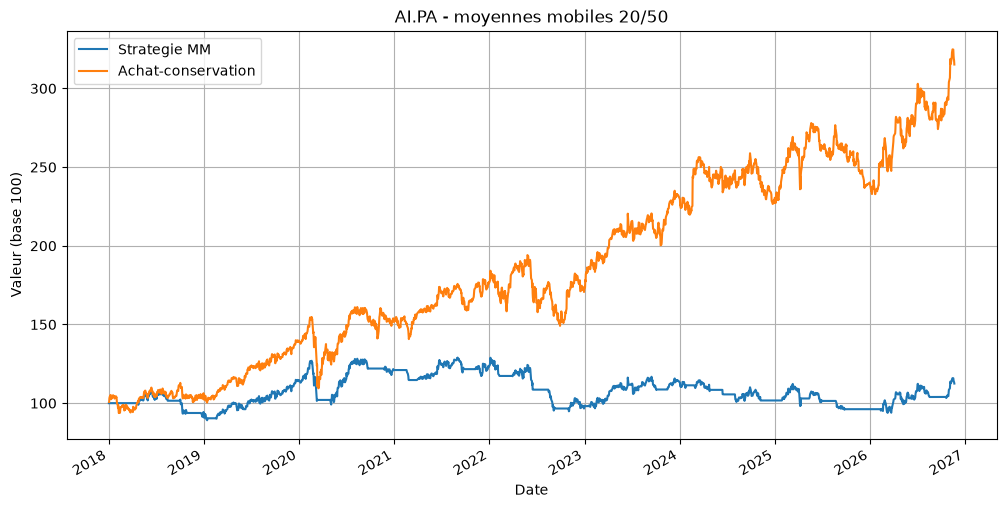

In [3]:
base = (1 + donnees["strategie"].dropna()).cumprod() * 100
benchmark = (1 + donnees["rendement"].dropna()).cumprod() * 100

ax = base.plot(figsize=(12, 6), label="Strategie MM")
benchmark.plot(ax=ax, label="Achat-conservation")
ax.set_title(f"{TICKER} - moyennes mobiles {COURTE}/{LONGUE}")
ax.set_ylabel("Valeur (base 100)")
ax.legend()
ax.grid(True)

## Lire un document local

Remplacez le chemin ci-dessous par celui d'un fichier CSV, TXT ou PDF.

In [4]:
chemin_document = racine / "backtest" / "synthese.csv"
print(lire_document(chemin_document))

           periode      debut        fin  strategie_Rendement annuel  strategie_Volatilité  strategie_Sharpe  strategie_Perte maximale  strategie_Rendement total  achat_conservation_Rendement annuel  achat_conservation_Volatilité  achat_conservation_Sharpe  achat_conservation_Perte maximale  achat_conservation_Rendement total
         2018-2020 2018-01-01 2021-01-01                      0.0647                0.1528              0.49                   -0.2191                     0.2104                               0.1462                         0.2186                       0.73                            -0.2928                              0.5149
         2021-2023 2021-01-01 2024-01-01                     -0.0025                0.1374              0.05                   -0.2647                    -0.0077                               0.1424                         0.1895                       0.80                            -0.2317                              0.5012
2024-a-aujourd-h